# Phase 2: Model Selection
Train and compare seven classifiers with 5-fold cross-validation to find the best models for detecting cognitive impairment.

## Step 1: Load the training features
Load the training patients' features and separate the inputs (23 features) from the label (0 = Normal, 1 = MCI/Dementia).

In [1]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name in ("phase1_data", "phase2_model") else Path.cwd()
train = pd.read_csv(ROOT / "data" / "processed" / "features_train.csv")

X = train.drop(columns=["patient", "label"])
y = train["label"]

print("Patients:", len(train), "| Features:", X.shape[1])
print(y.value_counts())

Patients: 167 | Features: 23
label
1    118
0     49
Name: count, dtype: int64


**Result:** 167 training patients with 23 features: 118 impaired (71%) and 49 normal (29%). Because of this imbalance, models are compared by F1 and AUC rather than accuracy.

## Step 2: Set up cross-validation and a baseline
Use 5-fold stratified cross-validation, so every fold keeps the same Normal/Impaired ratio. A "dummy" model that always predicts the majority class sets the minimum score to beat.

In [2]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
SCORING = ["accuracy", "precision", "recall", "f1", "roc_auc"]

def evaluate(model):
    s = cross_validate(model, X, y, cv=cv, scoring=SCORING, return_train_score=True)
    return {m: (s[f"test_{m}"].mean(), s[f"test_{m}"].std(), s[f"train_{m}"].mean()) for m in SCORING}

base = evaluate(DummyClassifier(strategy="most_frequent"))
for m, (val, std, tr) in base.items():
    print(f"{m:9s} validation {val:.3f} ± {std:.3f}")

accuracy  validation 0.707 ± 0.011
precision validation 0.707 ± 0.011
recall    validation 1.000 ± 0.000
f1        validation 0.828 ± 0.008
roc_auc   validation 0.500 ± 0.000


**Result:** The dummy model labels everyone as impaired and still reaches 70.7% accuracy and 0.83 F1, but its AUC is 0.50 (no real ability to tell groups apart) and it never identifies a normal person. So accuracy and F1 alone are misleading here; models are judged mainly by AUC, balanced accuracy and macro F1.

## Step 3: Train and compare the seven models
Train Logistic Regression, Decision Tree, Random Forest, SVM, KNN, Naive Bayes and XGBoost with the same 5 folds. Models sensitive to scale use StandardScaler, and class weights are balanced where supported.

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

SCORING = ["roc_auc", "balanced_accuracy", "f1_macro", "recall", "accuracy"]
ratio = (y == 0).sum() / (y == 1).sum()

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)),
    "Decision Tree":       DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=300, max_depth=5, class_weight="balanced", random_state=42),
    "SVM":                 make_pipeline(StandardScaler(), SVC(class_weight="balanced", probability=True, random_state=42)),
    "KNN":                 make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)),
    "Naive Bayes":         make_pipeline(StandardScaler(), GaussianNB()),
    "XGBoost":             XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                                         scale_pos_weight=ratio, random_state=42, eval_metric="logloss"),
}

rows = []
for name, model in models.items():
    s = cross_validate(model, X, y, cv=cv, scoring=SCORING, return_train_score=True)
    row = {"model": name}
    for m in SCORING:
        row[m] = round(s[f"test_{m}"].mean(), 3)
    row["auc_std"] = round(s["test_roc_auc"].std(), 3)
    row["train_auc"] = round(s["train_roc_auc"].mean(), 3)
    rows.append(row)

results = pd.DataFrame(rows).sort_values("roc_auc", ascending=False).reset_index(drop=True)
(ROOT / "phase2_model" / "results").mkdir(parents=True, exist_ok=True)
results.to_csv(ROOT / "phase2_model" / "results" / "model_comparison.csv", index=False)
results

,model,roc_auc,balanced_accuracy,f1_macro,recall,accuracy,auc_std,train_auc
0,Logistic Regression,0.641,0.583,0.553,0.602,0.592,0.064,0.813
1,Naive Bayes,0.641,0.579,0.550,0.568,0.576,0.066,0.746
2,SVM,0.640,0.616,0.594,0.643,0.629,0.047,0.951
3,Random Forest,0.596,0.543,0.525,0.924,0.701,0.087,1.000
4,Decision Tree,0.577,0.599,0.561,0.593,0.599,0.140,0.891
5,KNN,0.544,0.522,0.499,0.899,0.676,0.068,0.744
6,XGBoost,0.525,0.510,0.502,0.755,0.611,0.050,1.000


**Result:** The simple models perform best: Logistic Regression and Naive Bayes reach AUC 0.64, and SVM has the best balanced accuracy (0.62) and macro F1 (0.59). Tree-based models (Random Forest, XGBoost) overfit strongly: perfect training AUC (1.00) but only 0.53–0.60 on validation. All top models clearly beat the dummy baseline (AUC 0.50), but the signal is moderate.

## Step 4: Confusion matrices and ROC curves for the top 3 models
Use cross-validated predictions to see how each top model classifies normal and impaired patients, and plot their ROC curves.

SVM                  sensitivity 1.00 | specificity 0.00
Logistic Regression  sensitivity 0.60 | specificity 0.57
Naive Bayes          sensitivity 0.57 | specificity 0.59


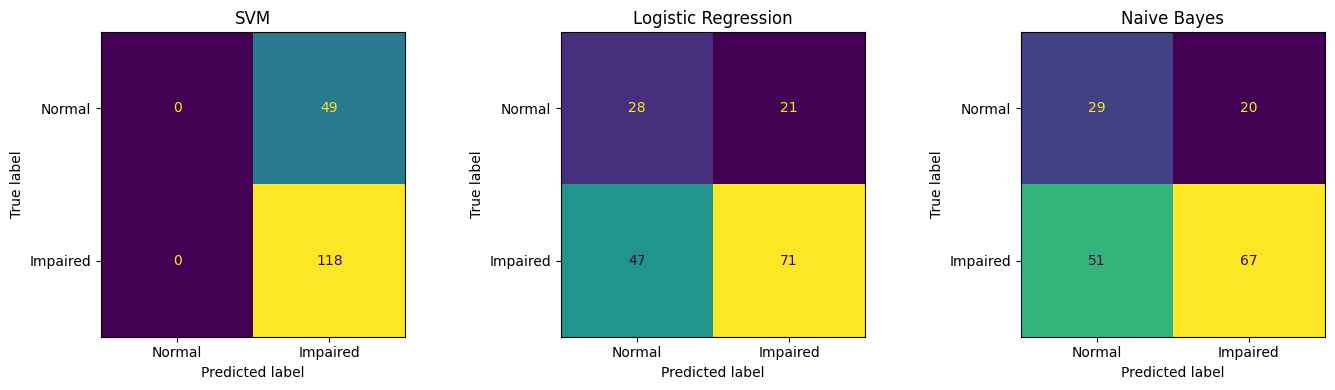

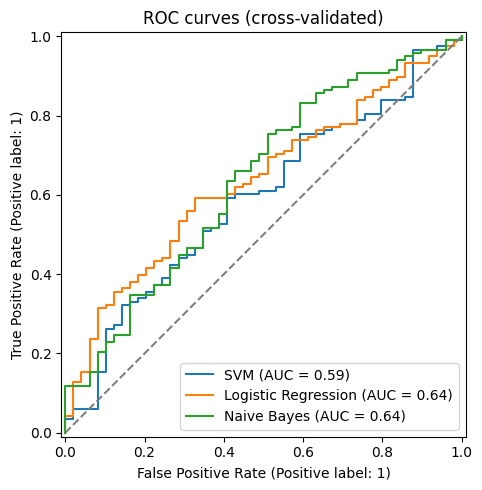

In [4]:
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, confusion_matrix

top = ["SVM", "Logistic Regression", "Naive Bayes"]
RES = ROOT / "phase2_model" / "results"

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig_roc, ax_roc = plt.subplots(figsize=(6, 5))
for ax, name in zip(axes, top):
    proba = cross_val_predict(models[name], X, y, cv=cv, method="predict_proba")[:, 1]
    pred = (proba >= 0.5).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=["Normal", "Impaired"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
    RocCurveDisplay.from_predictions(y, proba, name=name, ax=ax_roc)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    print(f"{name:20s} sensitivity {tp/(tp+fn):.2f} | specificity {tn/(tn+fp):.2f}")

ax_roc.plot([0, 1], [0, 1], "--", color="gray")
ax_roc.set_title("ROC curves (cross-validated)")
fig.tight_layout(); fig.savefig(RES / "confusion_matrices_top3.png", dpi=150)
fig_roc.tight_layout(); fig_roc.savefig(RES / "roc_top3.png", dpi=150)
plt.show()

## Step 5: Which groups can the model tell apart?
Check whether the language signal is stronger for dementia than for MCI, by comparing Normal vs Dementia only, and Normal vs MCI only.

In [5]:
info = pd.read_csv(ROOT / "data" / "processed" / "patient_info.csv")[["patient", "group"]]
data = train.merge(info, on="patient")

lr = models["Logistic Regression"]
for g in ["Dementia", "MCI"]:
    sub = data[data["group"].isin(["Normal", g])]
    Xs = sub.drop(columns=["patient", "label", "group"])
    ys = (sub["group"] == g).astype(int)
    s = cross_validate(lr, Xs, ys, cv=cv, scoring=["roc_auc", "balanced_accuracy"])
    print(f"Normal vs {g:8s} ({len(sub)} patients) → AUC {s['test_roc_auc'].mean():.3f} ± {s['test_roc_auc'].std():.3f}"
          f" | balanced acc {s['test_balanced_accuracy'].mean():.3f}")

Normal vs Dementia (72 patients) → AUC 0.632 ± 0.194 | balanced acc 0.623
Normal vs MCI      (144 patients) → AUC 0.627 ± 0.083 | balanced acc 0.601


**Result:** The model separates Normal from Dementia (AUC 0.63) about as well as Normal from MCI (AUC 0.63). The dementia comparison varies much more between folds (± 0.19) because it has only 72 patients, so we cannot claim the signal is stronger for dementia. The language features carry a similar, moderate signal for both levels of impairment.

## Step 6: Summary and decision
- 7 models were compared with 5-fold stratified cross-validation on 167 training patients.
- A dummy baseline shows that accuracy and F1 are misleading here (70.7% accuracy by predicting everyone as impaired), so models were judged by AUC, balanced accuracy and macro F1.
- Simple models performed best: Logistic Regression and Naive Bayes (AUC 0.64). Random Forest and XGBoost overfit (training AUC 1.00, validation 0.53–0.60).
- SVM needs threshold tuning (at 0.5 it labels everyone as impaired).
- The signal is similar for MCI and Dementia (AUC ~0.63 each), so we keep one binary model: Normal vs Impaired.

**Models taken to the final notebook:** Logistic Regression, Naive Bayes, and SVM (with threshold tuning).